# Testing DLP: Training a Basic FNN

In this notebook, we construct and run a basic FNN to make sure that functionality is established. Creation Date: July 27 2018.

In [21]:
import sys
PYTHONPATH="../"
sys.path.append(PYTHONPATH)
import models 
from train import * 
import matplotlib.pyplot as py 
%matplotlib inline 

In [2]:
# first, let's generate the input data 
# this function is contained in train.py 
train_file = "../Preprocess/preprocess_outputs/train_DLP_Test.h5"
val_file = "../Preprocess/preprocess_outputs/val_DLP_Test.h5"
weight_file = "../Preprocess/preprocess_outputs/weight_DLP_Test.h5"
num_classes = 3
X_train, X_val, Y_train, Y_val, X_weights = models.fnn_input(train_file, val_file, weight_file, num_classes)

In [3]:
# let's explore the output of fnn_input to make sure it's correctly formatted 
type(X_train) # --> numpy array 
print(X_train.shape)
# shape is (979, 46) --> 979 jets, 46 variables per jet 
print(X_val.shape) 
print(Y_train.shape)
print(Y_val.shape)
print(X_weights.shape)
# looks like the validation set has one less jet than the training set 
# in this data; not sure why this is the case 

(979, 46)
(978, 46)
(979, 3)
(978, 3)
(979,)


In [4]:
# let's try to construct a one-layer FNN with our FNN class 
num_vars = X_train.shape[1] 
print(num_jets)
print(num_vars)

# construct the model 
myModel = models.FNN(input_dim=num_vars, num_hidden=1, hidden_dims=[100], modelName="first_test")

979
46


In [5]:
# now that the model is contructed, let's do some training 
hyperParams = [1e-5, 0, 0, 50, 50]
first_history = fnn_train(myModel, X_train, X_val, Y_train, Y_val, X_weights, hyperParams, filepath="../Results/first_test.h5")

Train on 979 samples, validate on 978 samples
Epoch 1/50
979/979 [==============================] - 0s - loss: 2.0859 - acc: 0.2942 - val_loss: 1.4492 - val_acc: 0.2352
Epoch 2/50
979/979 [==============================] - 0s - loss: 2.0850 - acc: 0.2799 - val_loss: 1.4553 - val_acc: 0.2229
Epoch 3/50
979/979 [==============================] - 0s - loss: 2.1006 - acc: 0.2860 - val_loss: 1.4638 - val_acc: 0.2311
Epoch 4/50
979/979 [==============================] - 0s - loss: 1.9627 - acc: 0.2870 - val_loss: 1.4733 - val_acc: 0.2352
Epoch 5/50
979/979 [==============================] - 0s - loss: 2.0717 - acc: 0.2676 - val_loss: 1.4826 - val_acc: 0.2423
Epoch 6/50
979/979 [==============================] - 0s - loss: 2.1668 - acc: 0.2768 - val_loss: 1.4911 - val_acc: 0.2485
Epoch 7/50
979/979 [==============================] - 0s - loss: 2.0447 - acc: 0.2911 - val_loss: 1.4988 - val_acc: 0.2556
Epoch 8/50
979/979 [==============================] - 0s - loss: 2.1056 - acc: 0.2697 - val_l

In [6]:
# looks like it works! 
# let's explore the output 
type(first_history)

keras.callbacks.History

In [12]:
print(first_history.history.keys())

['acc', 'loss', 'val_acc', 'val_loss']


In [17]:
# so first_history.history is a dictionary with the above keys 
print(first_history.history['val_acc'])

[0.23517382701055159, 0.22290388825359034, 0.23108384564732237, 0.2351738243441884, 0.24233129062901246, 0.24846626123402016, 0.2556237227346268, 0.25766871246396889, 0.26073619610570936, 0.26482617518348439, 0.27198364095027217, 0.27607362269441044, 0.28016360101036741, 0.28323108579483502, 0.28629856829384842, 0.29141104318856703, 0.2944785287348527, 0.29754601351932025, 0.2985685074317187, 0.30470347776247192, 0.30981595055457273, 0.31390593001325684, 0.32004089958219195, 0.32106339197095429, 0.32822086002319623, 0.33231084024369839, 0.33844580752717934, 0.34151329078801085, 0.34662576644454751, 0.35173824191824793, 0.35685071528933043, 0.36196318789859488, 0.36707566507876771, 0.37218813921166832, 0.37832310725696733, 0.38139059204143494, 0.39161554079479965, 0.39570551949166571, 0.40286298525845349, 0.40593046986008469, 0.4069529668197554, 0.41308793486505441, 0.41717791356192047, 0.42024539987002413, 0.42433538313779851, 0.42740286612437545, 0.43660531590686985, 0.438650304493484

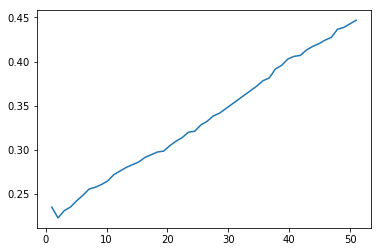

In [23]:
# let's try to make a simple plot of epoch vs. validation accuracy 
epochs = np.linspace(1, 51)
val_acc = first_history.history['val_acc']
py.plot(epochs, val_acc)

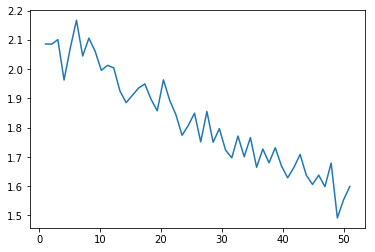

In [24]:
loss = first_history.history['loss']
py.plot(epochs, loss)